# Detecção de Objetos com YOLO — YOLOv8n vs YOLO11n

**Objetivo:** implementar e treinar o YOLO numa base de dados real, gerar predições com as *bounding boxes* desenhadas e comparar duas versões do modelo.

- **Base de dados:** [African Wildlife](https://docs.ultralytics.com/datasets/detect/african-wildlife/) — ~1.500 imagens de animais da savana africana com 4 classes: `buffalo`, `elephant`, `rhino`, `zebra`. Divisão: 1.052 treino / 225 validação / 227 teste.
- **Modelos comparados:** **YOLOv8n** (2023) e **YOLO11n** (2024), ambos na variante *nano*, partindo de pesos pré-treinados no COCO (*transfer learning*).
- **Biblioteca:** [Ultralytics](https://github.com/ultralytics/ultralytics).

> Para rodar no Colab: `Ambiente de execução → Alterar tipo de ambiente → GPU (T4)`. Com GPU, dá para subir `EPOCHS` para 50 e `IMGSZ` para 640 (melhor resultado). As saídas salvas neste notebook foram geradas em CPU com a configuração mais leve abaixo.

## 1. Instalação

In [1]:
!pip install -q ultralytics
import ultralytics, torch
ultralytics.checks()
print('GPU disponível:', torch.cuda.is_available())

Ultralytics 8.4.193 🚀 Python-3.13.18 torch-2.15.0+cu132 CPU (Intel Xeon Processor @ 2.10GHz)


Setup complete ✅ (2 CPUs, 7.8 GB RAM, 230.4/252.0 GB disk)


GPU disponível: False


## 2. Configuração do experimento
Os dois modelos são treinados com **exatamente os mesmos hiperparâmetros**, para a comparação ser justa.

In [2]:
import torch
GPU = torch.cuda.is_available()

DATA   = 'african-wildlife.yaml'   # baixado automaticamente pela Ultralytics
EPOCHS = 50 if GPU else 12
IMGSZ  = 640 if GPU else 320
BATCH  = 16
SEED   = 0
import os
PROJ   = os.path.abspath('runs')   # pasta onde ficam todos os resultados

MODELOS = {'YOLOv8n': 'yolov8n.pt', 'YOLO11n': 'yolo11n.pt'}
print(f'EPOCHS={EPOCHS}  IMGSZ={IMGSZ}  BATCH={BATCH}  device={"GPU" if GPU else "CPU"}')

EPOCHS=12  IMGSZ=320  BATCH=16  device=CPU


## 3. Base de dados
Download e visualização de algumas imagens de treino com as anotações originais (*ground truth*).

In [3]:
from ultralytics.data.utils import check_det_dataset
info = check_det_dataset(DATA)
CLASSES = info['names']
print('Classes:', CLASSES)

from pathlib import Path
for split in ['train', 'val', 'test']:
    n = len(list(Path(info[split]).glob('*.jpg')))
    print(f'{split:>5}: {n} imagens')

Classes: {0: 'buffalo', 1: 'elephant', 2: 'rhino', 3: 'zebra'}
train: 1049 imagens
  val: 225 imagens
 test: 227 imagens


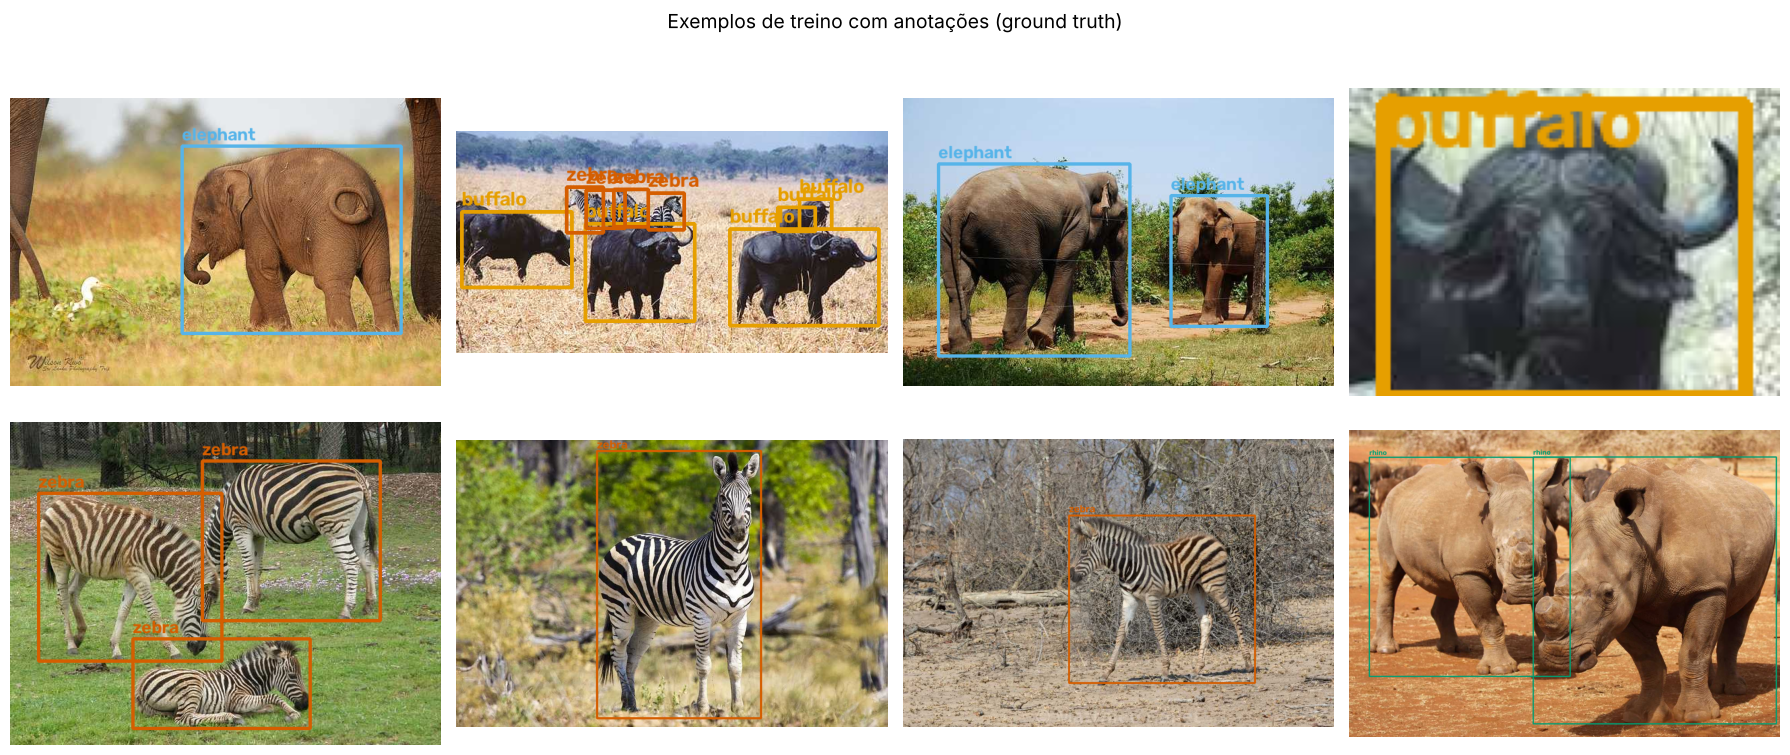

In [4]:
import random, cv2, matplotlib.pyplot as plt
from pathlib import Path

CORES = {0: (230, 159, 0), 1: (86, 180, 233), 2: (0, 158, 115), 3: (213, 94, 0)}

def desenha_gt(img_path):
    img = cv2.cvtColor(cv2.imread(str(img_path)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    lbl = Path(str(img_path).replace('/images/', '/labels/')).with_suffix('.txt')
    for linha in lbl.read_text().split('\n') if lbl.exists() else []:
        if not linha.strip(): continue
        c, x, y, bw, bh = map(float, linha.split())
        x1, y1 = int((x - bw/2) * w), int((y - bh/2) * h)
        x2, y2 = int((x + bw/2) * w), int((y + bh/2) * h)
        cv2.rectangle(img, (x1, y1), (x2, y2), CORES[int(c)], 3)
        cv2.putText(img, CLASSES[int(c)], (x1, max(y1 - 8, 20)), cv2.FONT_HERSHEY_SIMPLEX, 0.9, CORES[int(c)], 2)
    return img

random.seed(1)
amostra = random.sample(sorted(Path(info['train']).glob('*.jpg')), 8)
fig, axs = plt.subplots(2, 4, figsize=(18, 8))
for ax, p in zip(axs.flat, amostra):
    ax.imshow(desenha_gt(p)); ax.axis('off')
plt.suptitle('Exemplos de treino com anotações (ground truth)', fontsize=14)
plt.tight_layout(); plt.show()

## 4. Treinamento
Cada modelo é treinado a partir dos pesos pré-treinados no COCO (*fine-tuning*).

In [5]:
from ultralytics import YOLO
import time

tempos = {}
for nome, pesos in MODELOS.items():
    print(f'\n===== Treinando {nome} =====')
    t0 = time.time()
    YOLO(pesos).train(data=DATA, epochs=EPOCHS, imgsz=IMGSZ, batch=BATCH, seed=SEED,
                      project=PROJ, name=nome, exist_ok=True, workers=2, verbose=False)
    tempos[nome] = (time.time() - t0) / 60
    print(f'{nome}: {tempos[nome]:.1f} min')

===== Treinando YOLOv8n =====
YOLOv8n: 22.3 min
===== Treinando YOLO11n =====
YOLO11n: 22.0 min


## 5. Curvas de treinamento
Evolução do mAP@50 e da *loss* de validação a cada época.

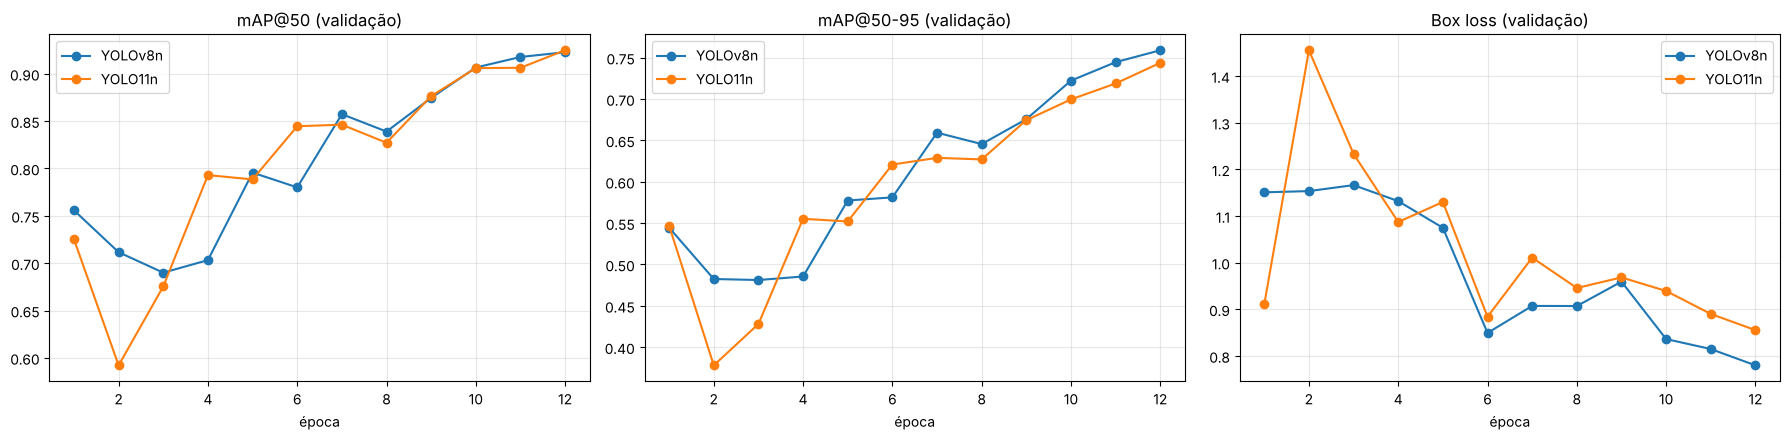

In [6]:
import pandas as pd
fig, axs = plt.subplots(1, 3, figsize=(18, 4.5))
for nome in MODELOS:
    df = pd.read_csv(f'{PROJ}/{nome}/results.csv'); df.columns = df.columns.str.strip()
    axs[0].plot(df['epoch'], df['metrics/mAP50(B)'], marker='o', label=nome)
    axs[1].plot(df['epoch'], df['metrics/mAP50-95(B)'], marker='o', label=nome)
    axs[2].plot(df['epoch'], df['val/box_loss'], marker='o', label=nome)
for ax, t in zip(axs, ['mAP@50 (validação)', 'mAP@50-95 (validação)', 'Box loss (validação)']):
    ax.set_title(t); ax.set_xlabel('época'); ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

## 6. Avaliação no conjunto de **teste**
O conjunto de teste não foi visto em nenhum momento do treino.

In [7]:
linhas, por_classe = [], {}
for nome in MODELOS:
    m = YOLO(f'{PROJ}/{nome}/weights/best.pt')
    r = m.val(data=DATA, split='test', imgsz=IMGSZ, batch=BATCH, project=PROJ, name=f'{nome}_test',
              exist_ok=True, verbose=False)
    n_params = sum(p.numel() for p in m.model.parameters())
    linhas.append({
        'Modelo': nome,
        'Precisão': r.box.mp, 'Recall': r.box.mr,
        'mAP@50': r.box.map50, 'mAP@50-95': r.box.map,
        'Parâmetros (M)': n_params / 1e6,
        'Inferência (ms/img)': r.speed['inference'],
        'Tempo de treino (min)': tempos.get(nome, float('nan')),
    })
    por_classe[nome] = {CLASSES[i]: r.box.maps[i] for i in range(len(CLASSES))}

tabela = pd.DataFrame(linhas).set_index('Modelo')
tabela.style.format('{:.3f}').format('{:.2f}', subset=['Parâmetros (M)', 'Inferência (ms/img)', 'Tempo de treino (min)'])

Ultralytics 8.4.193 🚀 Python-3.13.18 torch-2.15.0+cu132 CPU (Intel Xeon Processor @ 2.10GHz)


Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1822.3±829.7 MB/s, size: 49.8 KB)


val: Scanning /home/claude/datasets/african-wildlife/labels/test... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 4.2Kit/s 0.1s

val: New cache created: /home/claude/datasets/african-wildlife/labels/test.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 6% ╸─────────── 1/15 1.2s/it 0.4s<16.9s

... (36 outputs left out)

                   all        227        375      0.913        0.9      0.951      0.769


Speed: 0.3ms preprocess, 16.7ms inference, 0.0ms loss, 0.2ms postprocess per image


Results saved to /home/claude/yolo/runs/YOLO11n_test


,Precisão,Recall,mAP@50,mAP@50-95,Parâmetros (M),Inferência (ms/img),Tempo de treino (min)
Modelo,,,,,,,
YOLOv8n,0.944,0.903,0.966,0.791,3.14,19.98,22.33
YOLO11n,0.913,0.900,0.951,0.769,2.61,16.73,22.04


mAP@50-95 por classe (teste):


,YOLOv8n,YOLO11n
buffalo,0.842,0.796
elephant,0.758,0.750
rhino,0.868,0.860
zebra,0.697,0.669


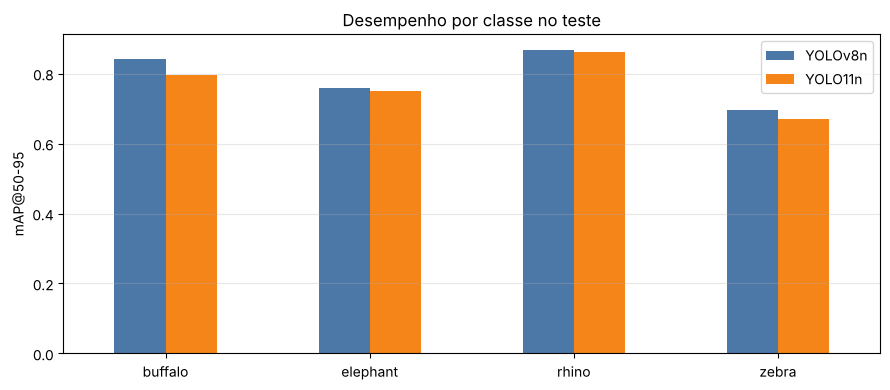

In [8]:
pc = pd.DataFrame(por_classe)
print('mAP@50-95 por classe (teste):')
display(pc.style.format('{:.3f}'))

ax = pc.plot.bar(figsize=(9, 4), rot=0, color=['#4C78A8', '#F58518'])
ax.set_ylabel('mAP@50-95'); ax.set_title('Desempenho por classe no teste'); ax.grid(axis='y', alpha=.3)
plt.tight_layout(); plt.show()

### Matrizes de confusão (teste)

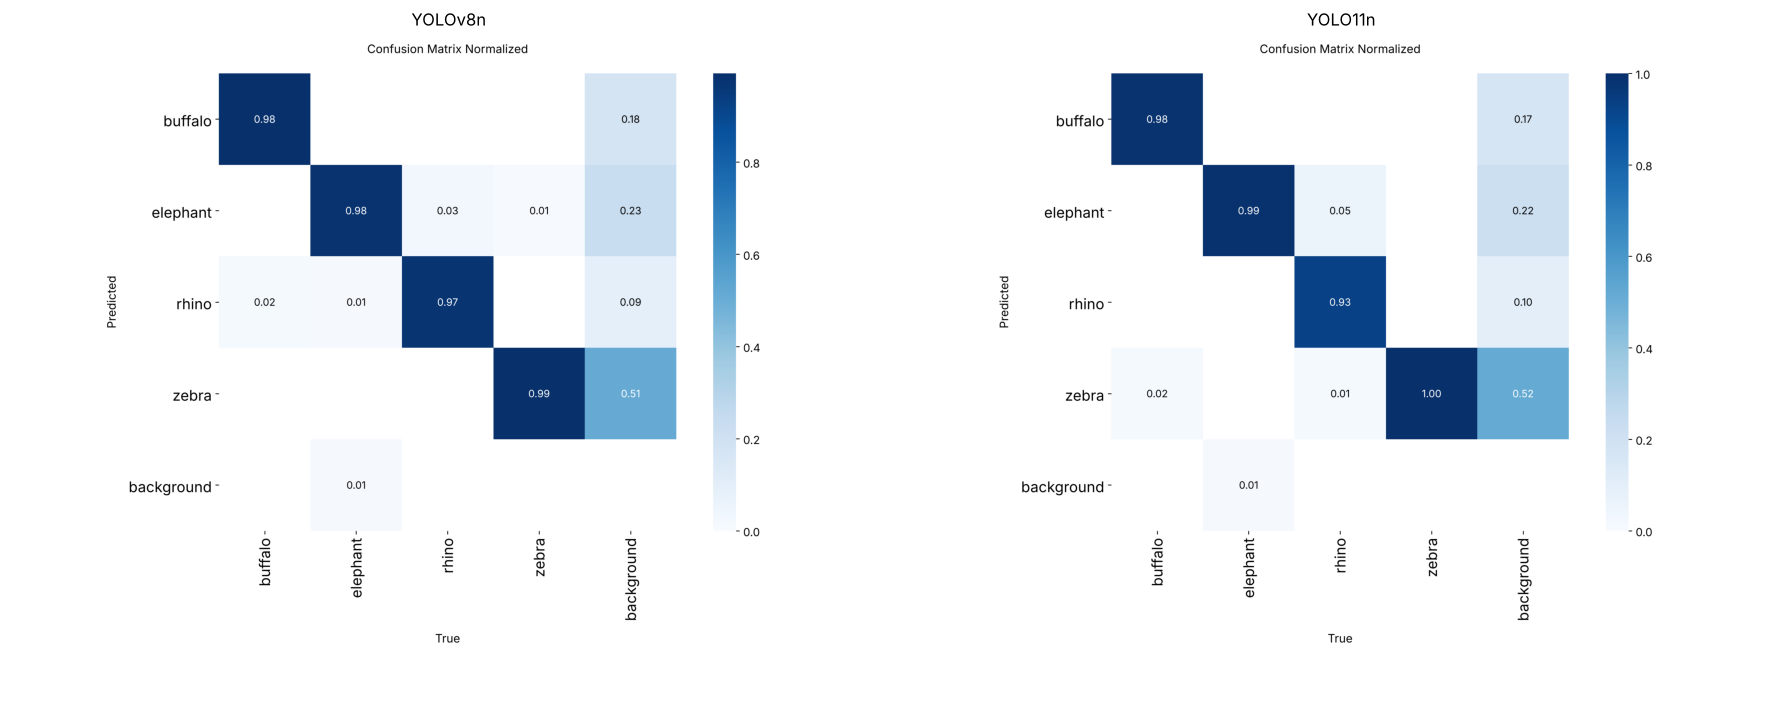

In [9]:
from IPython.display import Image as IPImage, display
fig, axs = plt.subplots(1, 2, figsize=(18, 7))
for ax, nome in zip(axs, MODELOS):
    ax.imshow(plt.imread(sorted(Path(f'{PROJ}/{nome}_test').glob('confusion_matrix_normalized*'))[0])); ax.set_title(nome); ax.axis('off')
plt.tight_layout(); plt.show()

## 7. Resultados com as bounding boxes
Predições dos dois modelos lado a lado nas mesmas imagens de teste (confiança mínima 0,4). As imagens anotadas também são salvas em `runs/<modelo>_pred/`.

Results saved to /home/claude/yolo/runs/YOLOv8n_pred


Results saved to /home/claude/yolo/runs/YOLO11n_pred


Results saved to /home/claude/yolo/runs/YOLOv8n_pred


Results saved to /home/claude/yolo/runs/YOLO11n_pred


Results saved to /home/claude/yolo/runs/YOLOv8n_pred


Results saved to /home/claude/yolo/runs/YOLO11n_pred


... (2 outputs left out)

Results saved to /home/claude/yolo/runs/YOLOv8n_pred


Results saved to /home/claude/yolo/runs/YOLO11n_pred


Results saved to /home/claude/yolo/runs/YOLOv8n_pred


Results saved to /home/claude/yolo/runs/YOLO11n_pred


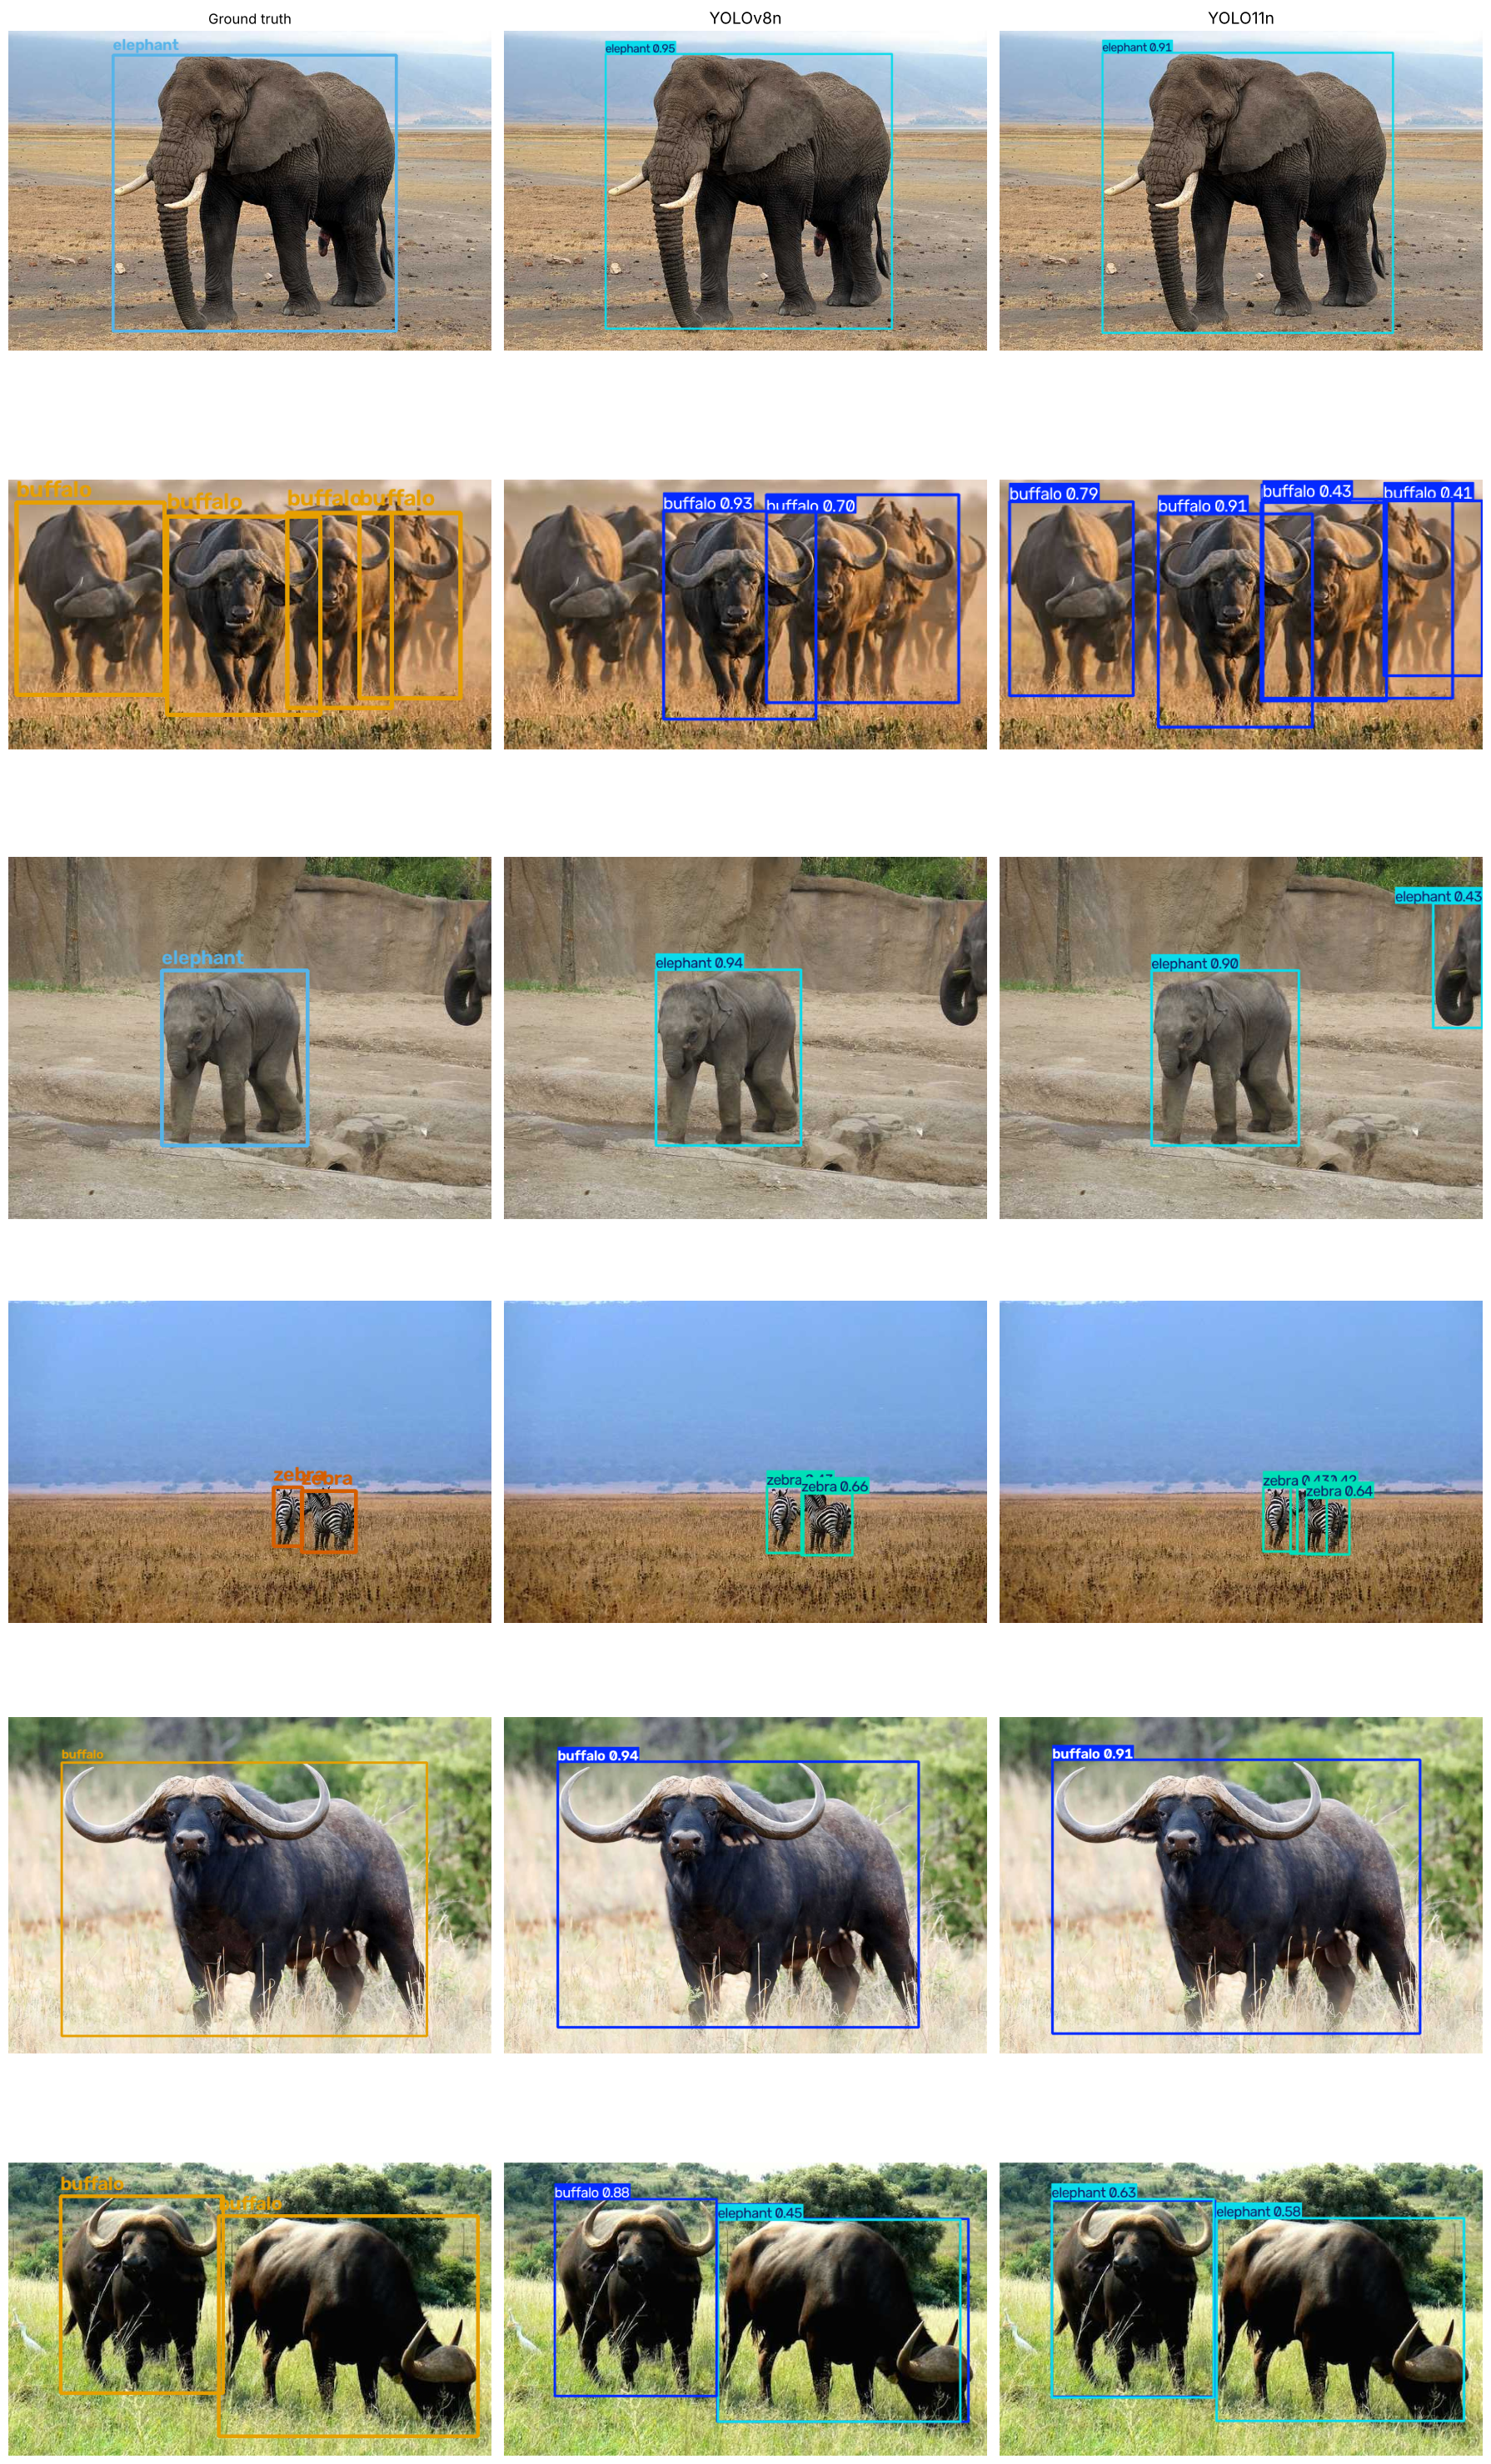

In [10]:
random.seed(7)
imgs_teste = random.sample(sorted(Path(info['test']).glob('*.jpg')), 6)

modelos = {n: YOLO(f'{PROJ}/{n}/weights/best.pt') for n in MODELOS}
fig, axs = plt.subplots(len(imgs_teste), 3, figsize=(18, 5.2 * len(imgs_teste)))
for i, p in enumerate(imgs_teste):
    axs[i, 0].imshow(desenha_gt(p)); axs[i, 0].set_title('Ground truth' if i == 0 else '')
    for j, (nome, m) in enumerate(modelos.items(), start=1):
        res = m.predict(p, imgsz=IMGSZ, conf=0.4, save=True, project=PROJ, name=f'{nome}_pred',
                        exist_ok=True, verbose=False)[0]
        axs[i, j].imshow(res.plot()[:, :, ::-1])
        if i == 0: axs[i, j].set_title(nome, fontsize=14)
    for ax in axs[i]: ax.axis('off')
plt.tight_layout(); plt.show()

## 8. Conclusão

Resultados no conjunto de **teste** (227 imagens), com 12 épocas a 320 px em CPU:

| Modelo | Precisão | Recall | mAP@50 | mAP@50-95 | Parâmetros | Inferência (CPU) |
|---|---|---|---|---|---|---|
| YOLOv8n | **0,944** | **0,903** | **0,966** | **0,791** | 3,14 M | 20,0 ms/img |
| YOLO11n | 0,913 | 0,900 | 0,951 | 0,769 | **2,61 M** | **16,7 ms/img** |

- **Os dois modelos aprenderam bem a tarefa**: mAP@50 acima de 0,95 com poucas épocas, graças ao *transfer learning* a partir do COCO (que já contém elefantes e zebras).
- **Precisão:** nesta configuração curta, o **YOLOv8n ficou ligeiramente à frente** (+2,2 pontos de mAP@50-95), e foi melhor em todas as 4 classes. A diferença é pequena e as curvas de validação de ambos **ainda estavam subindo na época 12**, ou seja, nenhum dos dois convergiu; com mais épocas (ex.: 50 em GPU) o resultado pode se inverter — a Ultralytics reporta o YOLO11n superior no COCO.
- **Eficiência:** o **YOLO11n é ~17% menor e ~16% mais rápido** na inferência, que é a principal proposta da versão 11 (blocos C3k2 e atenção C2PSA no lugar dos blocos C2f).
- **Classe mais difícil:** `zebra` (mAP@50-95 ≈ 0,67–0,70), por aparecer muitas vezes pequena e em grupo, com caixas sobrepostas. Nas predições visuais, ambos os modelos erram em manadas densas de búfalos (caixas faltando ou fundidas) e o YOLO11n confundiu búfalos com elefantes numa das imagens.

**Resumo:** com treino curto, o YOLOv8n entregou detecções um pouco mais precisas; o YOLO11n entrega quase a mesma qualidade com um modelo menor e mais rápido — melhor escolha quando a velocidade importa (ex.: câmeras de monitoramento de fauna).